# Train

Train a surrogate on the generated dataset. Pick a profile and an objective, optionally override some
fields, and run. A profile (in `src/erosion_sim/config.py`) sets the data and the model size. The
objective sets how the model is trained; every profile works with both:

- `"regression"`: the U-Net predicts the change directly.
- `"diffusion"`: the U-Net denoises the change, and predictions are samples (see
  `docs/plans/diffusion-plan.md`).

The best checkpoint (lowest validation loss) is saved to `artifacts/checkpoints/<objective>-<profile>.pt`, for
example `artifacts/checkpoints/diffusion-fixed_dt.pt`. The latest state is saved at every validation to
`artifacts/checkpoints/<objective>-<profile>-last.pt`; set `RESUME = True` to continue an interrupted run from it.
Look at the results in `notebooks/chunk/evaluate.ipynb`, which loads the checkpoint without retraining.

Profiles:

- `overfit`: memorize 10 pairs. A check that the pipeline works; about 1.5 minutes. For diffusion, the
  best-validation checkpoint is early, so look at the `-last.pt` file for memorization.
- `fixed_dt`: one elapsed time (10,000 yr), runs without uplift. Diffusion takes about 40 minutes on
  the laptop GPU.
- `variable_dt`: every elapsed time, runs without uplift, one pass over every pair.

For regression, the loss is the MSE (mean squared error) of the normalized change. For diffusion, it
is the EDM denoising loss, averaged over noise levels; it cannot be compared with the regression loss.
**Skill** is `1 - MSE / MSE(no change)`: 0 means no better than predicting no change, 1 is perfect.
For diffusion it scores one denoising step at fixed noise levels, not a full sample, so it reads
higher than the skill of real samples.

In [1]:
from dataclasses import asdict

from erosion_sim.config import get_config
from erosion_sim.train import train

In [2]:
PROFILE = "variable_dt"
OBJECTIVE = "diffusion"  # "regression" or "diffusion"
OVERRIDES = {}  # for example {"steps": 5_000, "lr": 1e-4}
RESUME = False  # continue from artifacts/checkpoints/<OBJECTIVE>-<PROFILE>-last.pt

cfg = get_config(PROFILE, OBJECTIVE)
for key, value in {**asdict(cfg), **OVERRIDES}.items():
    print(f"{key:<18} {value}")

profile            variable_dt
data_profile       full
objective          diffusion
runs               (('U', (0.0, 0.0)),)
lags               None
scale              fitted
max_train_samples  None
channels           (32, 64, 128, 256)
blocks             1
emb_dim            256
attention          True
batch_size         64
lr                 0.0003
weight_decay       0.0001
steps              20000
epochs             1.0
warmup_steps       500
eval_every         1000
val_samples        2048
patience           10
log_every          100
num_workers        8
compile            True
bf16               True
seed               0


variable_dt: 8,436,673 parameters, 3,399,150 training pairs, 2,048 validation pairs, device cuda


W1109 10:15:48.221000 1675812 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


step 100/53112  train loss 0.8476  lr 6.06e-05  98 samples/s
step 200/53112  train loss 0.5766  lr 1.21e-04  156 samples/s
step 300/53112  train loss 0.3152  lr 1.81e-04  195 samples/s
step 400/53112  train loss 0.1376  lr 2.41e-04  222 samples/s
step 500/53112  train loss 0.1114  lr 3.00e-04  242 samples/s
step 600/53112  train loss 0.1028  lr 3.00e-04  258 samples/s
step 700/53112  train loss 0.0942  lr 3.00e-04  271 samples/s
step 800/53112  train loss 0.0895  lr 3.00e-04  281 samples/s
step 900/53112  train loss 0.0835  lr 3.00e-04  290 samples/s
step 1000/53112  train loss 0.0772  lr 3.00e-04  297 samples/s
  validation loss 0.0667  skill vs no change 0.983  (saved best)
step 1100/53112  train loss 0.0733  lr 3.00e-04  286 samples/s
step 1200/53112  train loss 0.0680  lr 3.00e-04  292 samples/s
step 1300/53112  train loss 0.0654  lr 3.00e-04  298 samples/s
step 1400/53112  train loss 0.0632  lr 3.00e-04  303 samples/s
step 1500/53112  train loss 0.0601  lr 3.00e-04  307 samples/s


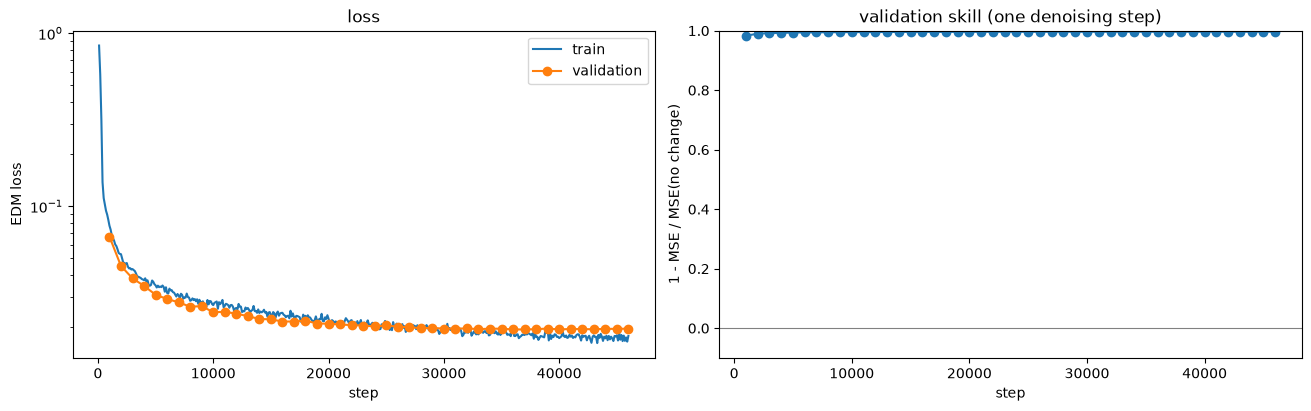

best checkpoint: /home/jay/Work/repos/erosion-sim-modeling/artifacts/diffusion-variable_dt.pt  (126.0 min)


In [3]:
history = train(cfg, resume=RESUME, **OVERRIDES)
print(f"best checkpoint: {history['checkpoint']}  ({history['seconds'] / 60:.1f} min)")